## TASK A — EDA

Use a retail CSV. Report shape, missingness, duplicates, distributions and three
findings.

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [45]:
df = pd.read_csv("retail-orders.csv")
df.head()

,order_id,line_no,ordered_at,customer_id,channel,country,category,units,unit_price_usd,discount_pct,revenue_usd,returned
0,O500860,1,2023-01-01 08:28:00,C5122,android,JP,beauty,4,26.09,0.20,83.49,False
1,O501250,1,2023-01-01 08:56:00,C4066,marketplace,JP,beauty,1,46.37,0.08,42.66,False
2,O502744,1,2023-01-01 15:57:00,C4877,ios,BR,grocery,2,23.67,0.00,47.34,False
3,O503708,1,2023-01-01 16:29:00,C4905,android,JP,apparel,1,35.09,0.00,35.09,False
4,O503708,2,2023-01-01 16:29:00,C4905,android,JP,apparel,2,56.24,0.00,112.48,False


In [46]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape: (7000, 12)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        7000 non-null   object 
 1   line_no         7000 non-null   int64  
 2   ordered_at      7000 non-null   object 
 3   customer_id     7000 non-null   object 
 4   channel         7000 non-null   object 
 5   country         7000 non-null   object 
 6   category        7000 non-null   object 
 7   units           7000 non-null   int64  
 8   unit_price_usd  7000 non-null   float64
 9   discount_pct    7000 non-null   float64
 10  revenue_usd     7000 non-null   float64
 11  returned        7000 non-null   bool   
dtypes: bool(1), float64(3), int64(2), object(6)
memory usage: 608.5+ KB


In [47]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
order_id          0
line_no           0
ordered_at        0
customer_id       0
channel           0
country           0
category          0
units             0
unit_price_usd    0
discount_pct      0
revenue_usd       0
returned          0
dtype: int64


In [48]:
print("\nExact Duplicate Rows:",df.duplicated().sum())

print("Duplicate Order Lines:",df.duplicated(subset=["order_id", "line_no"]).sum())


Exact Duplicate Rows: 0
Duplicate Order Lines: 0


In [49]:
print("\nStatistical Summary:")
print(df.describe())


Statistical Summary:
           line_no        units  unit_price_usd  discount_pct  revenue_usd
count  7000.000000  7000.000000     7000.000000   7000.000000  7000.000000
mean      1.584714     1.693286       72.662411      0.096569   110.560624
std       0.822057     1.162131       71.403657      0.119820   152.238442
min       1.000000     1.000000        6.070000      0.000000     5.320000
25%       1.000000     1.000000       28.405000      0.000000    33.200000
50%       1.000000     1.000000       48.860000      0.000000    60.100000
75%       2.000000     2.000000       81.712500      0.190000   125.300000
max       4.000000     6.000000      589.710000      0.450000  2317.580000


In [50]:
print("\nCategory Distribution:")
print(df["category"].value_counts())

print("\nChannel Distribution:")
print(df["channel"].value_counts())

print("\nReturn Distribution:")
print(df["returned"].value_counts())


Category Distribution:
category
apparel        1696
home           1279
grocery        1188
beauty         1088
electronics     960
sports          789
Name: count, dtype: int64

Channel Distribution:
channel
web            2734
ios            1729
android        1386
marketplace    1151
Name: count, dtype: int64

Return Distribution:
returned
False    6323
True      677
Name: count, dtype: int64


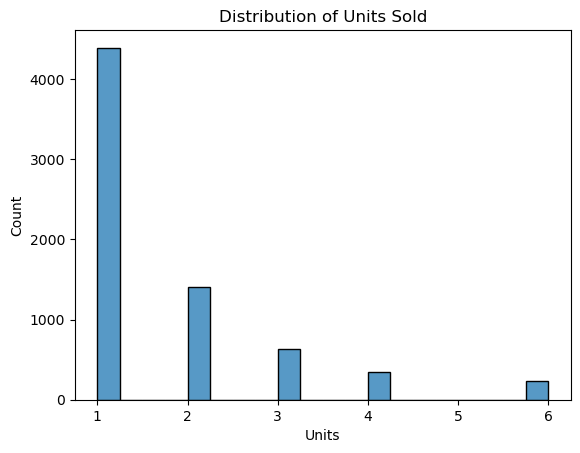

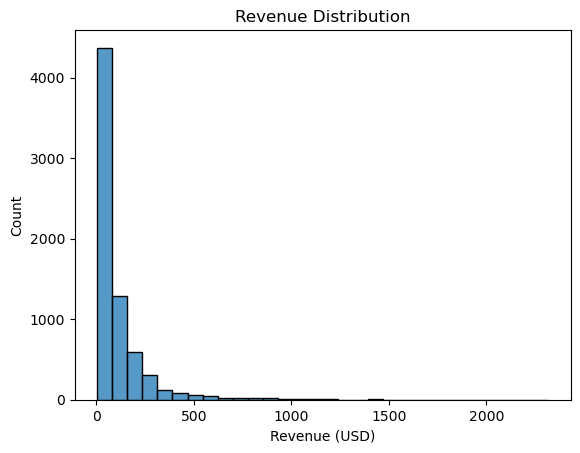

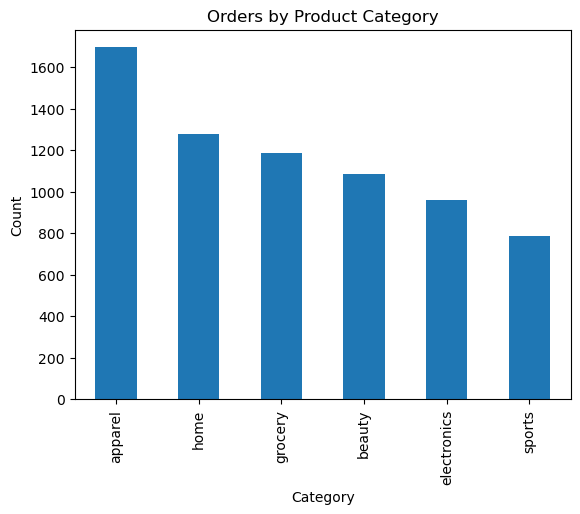

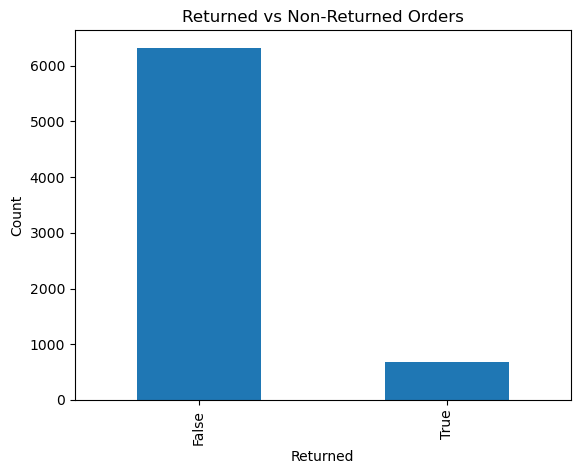

In [51]:
# 1. Units distribution
sns.histplot(df["units"], bins=20)
plt.title("Distribution of Units Sold")
plt.xlabel("Units")
plt.show()

# 2. Revenue distribution
sns.histplot(df["revenue_usd"], bins=30)
plt.title("Revenue Distribution")
plt.xlabel("Revenue (USD)")
plt.show()

# 3. Category distribution
df["category"].value_counts().plot(kind="bar")
plt.title("Orders by Product Category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.show()

# 4. Return distribution
df["returned"].value_counts().plot(kind="bar")
plt.title("Returned vs Non-Returned Orders")
plt.xlabel("Returned")
plt.ylabel("Count")
plt.show()

In [52]:
# Finding 1: Return rate by category
print("\nReturn Rate by Category:")
print(
    df.groupby("category")["returned"]
    .mean()
    .mul(100)
    .round(2)
)


Return Rate by Category:
category
apparel        20.70
beauty          5.70
electronics     8.85
grocery         1.26
home            4.22
sports         13.94
Name: returned, dtype: float64



Monthly Revenue:
ordered_at
1     43928.63
2     61029.42
3     64737.35
4     66741.55
5     65412.90
6     59971.01
7     67899.68
8     66063.63
9     52351.97
10    64170.75
11    69439.48
12    92178.00
Name: revenue_usd, dtype: float64


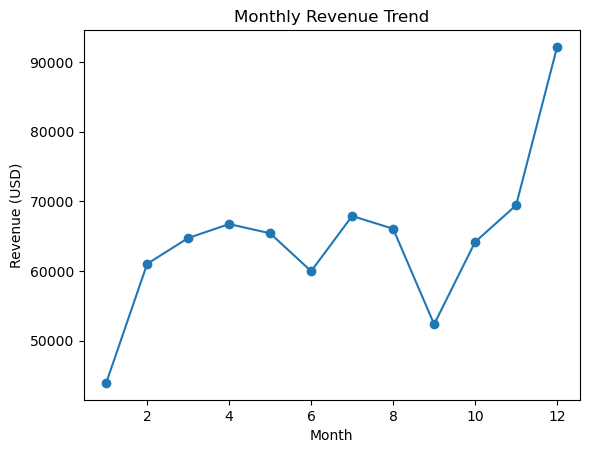

In [53]:
# Finding 2: Monthly revenue
df["ordered_at"] = pd.to_datetime(df["ordered_at"])

monthly_revenue = (
    df.groupby(df["ordered_at"].dt.month)["revenue_usd"]
    .sum()
)

print("\nMonthly Revenue:")
print(monthly_revenue)

monthly_revenue.plot(kind="line", marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (USD)")
plt.show()



In [54]:
# Finding 3: Return rate by sales channel
print("\nReturn Rate by Channel:")
print(
    df.groupby("channel")["returned"]
    .mean()
    .mul(100)
    .round(2)
)


Return Rate by Channel:
channel
android         9.74
ios             8.91
marketplace     9.56
web            10.17
Name: returned, dtype: float64


## TASK B — FEATURE ENGINEERING

Create order value, month, discount percentage and customer-level aggregates. 
Explain each feature.

In [55]:
# Convert order date to datetime
df["ordered_at"] = pd.to_datetime(df["ordered_at"])

# 1. Calculate order value before discount
df["order_value"] = (df["units"] * df["unit_price_usd"])

# 2. Extract month
df["month"] = df["ordered_at"].dt.month

# 3. Calculate discount percentage
df["discount_percentage"] = df["discount_pct"] * 100

# 4. Customer-level aggregates
customer_stats = df.groupby("customer_id").agg(
    total_orders=("order_id", "nunique"),
    total_units=("units", "sum"),
    total_spending=("revenue_usd", "sum"),
    average_order_value=("revenue_usd", "mean")
).reset_index()

df = df.merge(
    customer_stats,
    on="customer_id",
    how="left"
)

print(df[[
    "order_value",
    "month",
    "discount_percentage",
    "total_orders",
    "total_units",
    "total_spending",
    "average_order_value"
]].head())

   order_value  month  discount_percentage  total_orders  total_units  \
0       104.36      1                 20.0             2            6   
1        46.37      1                  8.0             1            1   
2        47.34      1                  0.0             4           12   
3        35.09      1                  0.0             4           14   
4       112.48      1                  0.0             4           14   

   total_spending  average_order_value  
0          123.55            61.775000  
1           42.66            42.660000  
2          422.02            70.336667  
3          706.96           100.994286  
4          706.96           100.994286  


Explanation of features:

Feature | Calculation | Purpose

order_value	Units × Unit price	Value before discount
month	Extracted from date	Identify seasonal trends
discount_percentage	Discount × 100	Express discount as percentage
total_orders	Unique order count per customer	Customer purchase frequency
total_units	Sum of units per customer	Customer purchase volume
total_spending	Sum of revenue per customer	Customer spending
average_order_value	Average revenue per line	Average purchase value per order line

## TASK C — MODEL

Create a leakage-safe classification pipeline and compare a majority-class baseline with logistic regression.

In [82]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,balanced_accuracy_score

In [58]:
# Create order-level features
df["ordered_at"] = pd.to_datetime(df["ordered_at"])

df["order_value"] = df["units"] * df["unit_price_usd"]

df["month"] = df["ordered_at"].dt.month

df["discount_percentage"] = df["discount_pct"] * 100

# Select input features
X = df[[
    "units",
    "unit_price_usd",
    "order_value",
    "month",
    "discount_percentage",
    "category",
    "channel",
    "country"
]]

# Target variable
y = df["returned"].astype(int)

# Split dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (5600, 8)
Testing Data: (1400, 8)


In [57]:
print(df.columns.tolist())

['order_id', 'line_no', 'ordered_at', 'customer_id', 'channel', 'country', 'category', 'units', 'unit_price_usd', 'discount_pct', 'revenue_usd', 'returned', 'order_value', 'month', 'discount_percentage', 'total_orders', 'total_units', 'total_spending', 'average_order_value']


In [60]:
num_features = [
    "units",
    "unit_price_usd",
    "order_value",
    "month",
    "discount_percentage"
]

cat_features = [
    "category",
    "channel",
    "country"
]

# Numerical preprocessing
num_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
cat_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", num_transformer, num_features),
    ("cat", cat_transformer, cat_features)
])

In [74]:
# Create baseline model
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

baseline_accuracy = accuracy_score(y_test,baseline_pred)

print(f"Baseline Accuracy: {baseline_accuracy*100:.2f}%")

Baseline Accuracy: 90.36%


In [104]:
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
        ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

log_reg_accuracy = accuracy_score(y_test, y_pred)

print(f"Logistic Regression Accuracy:{log_reg_accuracy*100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))


Logistic Regression Accuracy:65.36%

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.65      0.77      1265
           1       0.17      0.67      0.27       135

    accuracy                           0.65      1400
   macro avg       0.56      0.66      0.52      1400
weighted avg       0.87      0.65      0.72      1400



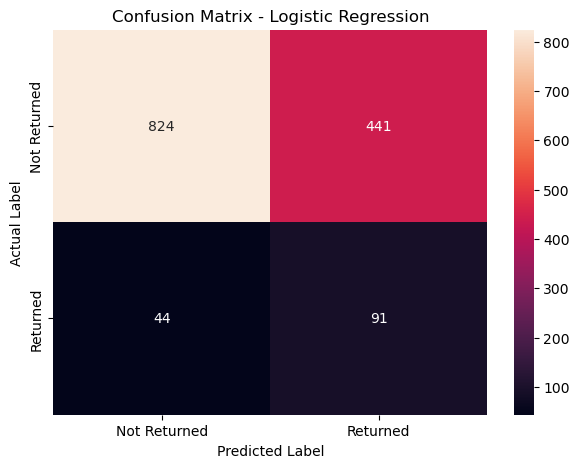

In [105]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Not Returned", "Returned"],
    yticklabels=["Not Returned", "Returned"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

Interpretation
- TN (1265): Correctly identified 1,265 orders that were not returned.
- FP (0): No non-returned orders were incorrectly classified as returned.
- FN (135): Failed to identify all 135 returned orders.
- TP (0): Did not correctly identify any returned orders.

The model achieves high accuracy simply by predicting the majority class.

In [106]:
# Compare model performance
print("MODEL COMPARISON")

print(f"Majority Baseline Accuracy: {baseline_accuracy*100:.2f}%")

print(f"Logistic Regression Accuracy: {log_reg_accuracy*100:.2f}%")

print(f"\nBaseline Balanced Accuracy: {balanced_accuracy_score(y_test, baseline_pred)*100:.2f}%")

print(f"Logistic Regression Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred)*100:.2f}%")

MODEL COMPARISON
Majority Baseline Accuracy: 90.36%
Logistic Regression Accuracy: 65.36%

Baseline Balanced Accuracy: 50.00%
Logistic Regression Balanced Accuracy: 66.27%


## Interpretation of Results

The Majority-Class Baseline and Logistic Regression achieved identical accuracy of 90.36% and balanced accuracy of 50%.

Although the accuracy appears high, it is influenced by class imbalance in the dataset, where non-returned orders form the majority class. Both models failed to effectively identify returned orders, resulting in a balanced accuracy of only 50%.

This indicates that Logistic Regression did not provide an improvement over the baseline model. Further improvements may require class balancing techniques, feature selection, and hyperparameter tuning.

## Conclusion

- High accuracy does not necessarily indicate good model performance, especially when working with imbalanced datasets. 
- Balanced accuracy, precision and recall are important evaluation metrics.